Net(
  (fc1): Linear(in_features=1, out_features=16, bias=True)
  (fc2): Linear(in_features=16, out_features=16, bias=True)
  (fc3): Linear(in_features=16, out_features=1, bias=True)
)
[Parameter containing:
tensor([[-0.0075],
        [ 0.5364],
        [-0.8230],
        [-0.7359],
        [-0.3852],
        [ 0.2682],
        [-0.0198],
        [ 0.7929],
        [-0.0887],
        [ 0.2646],
        [-0.3022],
        [-0.1966],
        [-0.9553],
        [-0.6623],
        [-0.4122],
        [ 0.0370]], requires_grad=True), Parameter containing:
tensor([ 0.3953,  0.6000, -0.6779, -0.4355,  0.3632,  0.8304, -0.2058,  0.7483,
        -0.1612,  0.1058,  0.9055, -0.9277, -0.6295, -0.2532, -0.3898,  0.8640],
       requires_grad=True), Parameter containing:
tensor([[-0.1620, -0.1151, -0.1747, -0.2341, -0.1459,  0.2149,  0.1116,  0.1212,
          0.0131, -0.1282,  0.0423, -0.2334, -0.1806, -0.1289,  0.1577,  0.1466],
        [-0.1109, -0.0090,  0.1599,  0.2485,  0.0992,  0.0338,  0.1676

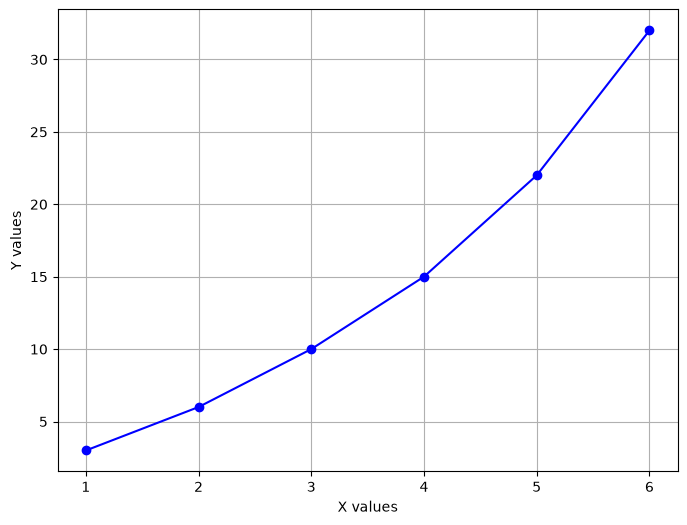

In [1]:
### Training with fancier version ###

import torch
import torch.nn as nn
import torch.nn.functional as F

import torch.optim as optim
import matplotlib.pyplot as plt

class Net(nn.Module): ## nn.Module class is used
    def __init__(self):
        torch.manual_seed(0)
        super(Net, self).__init__()
        self.fc1 = nn.Linear(1,16)
        self.fc2 = nn.Linear(16,16)
        self.fc3 = nn.Linear(16,1)
        
    def forward(self, x):
        x = (x - 3.5) / 2.5
        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        x = self.fc3(x)
        return x

net = Net()

print(net)
print(list(net.parameters())) # parameters are randomized


#def criterion(out, label):
#    return (label - out)**2
criterion = nn.MSELoss()


optimizer = optim.Adam(net.parameters(), lr=0.05)
#optimizer = optim.Adam(net.parameters(), lr=0.1)


data = [(1.0,3.0), (2.0,6.0), (3.0,10.0), (4.0,15.0), (5.0,22.0), (6.0,32.0)]

# Split data into x and y
x_values, y_values = zip(*data)

# Plotting
plt.figure(figsize=(8, 6))
plt.plot(x_values, y_values, marker='o', linestyle='-', color='b')
plt.xlabel('X values')
plt.ylabel('Y values')
plt.grid(True)
plt.show()

In [2]:
inputs = torch.FloatTensor([[x] for x, y in data])
labels = torch.FloatTensor([[y] for x, y in data])

for epoch in range(10000):
    optimizer.zero_grad()
    outputs = net(inputs)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()
    with torch.no_grad():
        loss = criterion(net(inputs), labels)
    if epoch == 0 or (epoch + 1) % 50 == 0 or loss.item() < 1e-5:
        print("Epoch {} - loss: {}".format(epoch + 1, loss.item()))
    if loss.item() < 1e-5:
        break
else:
    raise RuntimeError("Training did not reach MSE below 1e-5")


### Test the trained network ###            
for i, current_data in enumerate(data):
    X, Y = current_data
    X, Y = torch.FloatTensor([X]), torch.FloatTensor([Y])  
    out = net(torch.FloatTensor(X))  
    print("when x = {}, y = {}".format(X, out))
    

Epoch 1 - loss: 279.7319030761719
Epoch 50 - loss: 9.934516906738281
Epoch 100 - loss: 0.024694988504052162
Epoch 150 - loss: 0.0002745965321082622
Epoch 163 - loss: 4.8735860218585e-06
when x = tensor([1.]), y = tensor([2.9972], grad_fn=<ViewBackward0>)
when x = tensor([2.]), y = tensor([5.9974], grad_fn=<ViewBackward0>)
when x = tensor([3.]), y = tensor([10.0009], grad_fn=<ViewBackward0>)
when x = tensor([4.]), y = tensor([15.0014], grad_fn=<ViewBackward0>)
when x = tensor([5.]), y = tensor([22.0030], grad_fn=<ViewBackward0>)
when x = tensor([6.]), y = tensor([32.0018], grad_fn=<ViewBackward0>)


In [3]:
X

tensor([6.])

In [4]:
for epoch in range(20):
    print(epoch)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19


In [5]:
W = torch.tensor([1.0], requires_grad=True)
W = W*2
label = 1.0
loss = W*5 - label 
loss.backward()
W.grad

/var/folders/yj/gx_cp2255q7_5bglq236my680000gn/T/ipykernel_2609/353321738.py:6: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at /Users/runner/work/pytorch/pytorch/build/aten/src/ATen/core/TensorBody.h:493.)
  W.grad
